# Chapter 4. Training Models — Practice Notebook

## Linear Regression

Generating linear synthetic data using: $y = 4 + 3x + \text{Gaussian noise}$.

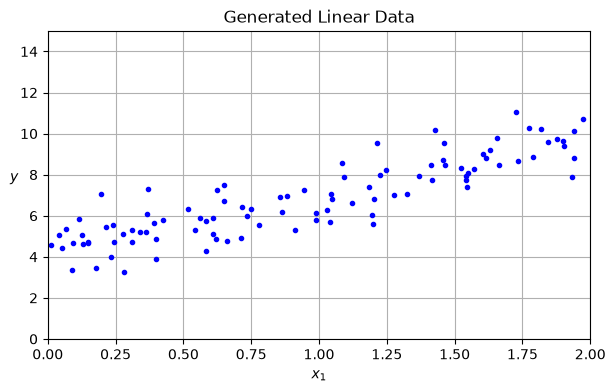

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.title("Generated Linear Data")
plt.show()

**Output meaning:** A scattered cloud of 100 points trending upwards around the true line $y = 4 + 3x$. The noise keeps them from being perfectly aligned.

### The Normal Equation

Computing $\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$ directly in one step. We add $x_0 = 1$ to `X` for the bias term $\theta_0$.

In [2]:
X_b = np.c_[np.ones((100, 1)), X]  # add x0 = 1
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Estimated theta_0 (intercept):", theta_best[0][0])
print("Estimated theta_1 (slope):    ", theta_best[1][0])

Estimated theta_0 (intercept): 4.21509615754675
Estimated theta_1 (slope):     2.7701133864384806


**Output meaning:** The model found $\theta_0 \approx 4.215$ and $\theta_1 \approx 2.770$ (very close to true $4$ and $3$). The slight difference is due to the random noise.

### Making Predictions with The Normal Equation

Predicting $y$ on new points ($x_1 = 0$ and $x_1 = 2$) and plotting the fitted line.

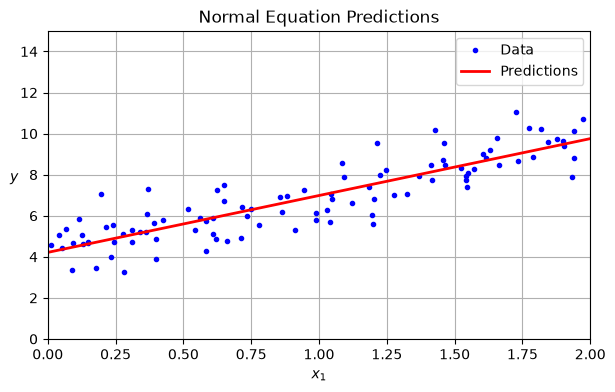

In [3]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b @ theta_best

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.", label="Data")
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend()
plt.title("Normal Equation Predictions")
plt.show()

**Output meaning:** The red regression line cuts straight through the middle of the points, minimizing the Mean Squared Error (MSE).

### Computational Complexity & SVD Pseudoinverse

Scikit-Learn's `LinearRegression` uses SVD pseudoinverse ($\hat{\mathbf{\theta}} = \mathbf{X}^+ \mathbf{y}$) instead of inverting $(\mathbf{X}^T \mathbf{X})$ directly.

In [4]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Intercept (theta_0):", lin_reg.intercept_)
print("Slope (theta_1):    ", lin_reg.coef_)
print("Predictions on [0, 2]:\n", lin_reg.predict(X_new))

Intercept (theta_0): [4.21509616]
Slope (theta_1):     [[2.77011339]]
Predictions on [0, 2]:
 [[4.21509616]
 [9.75532293]]


In [5]:
# Direct SVD pseudoinverse via NumPy: theta = pinv(X_b) @ y
theta_svd = np.linalg.pinv(X_b) @ y
print("Theta via np.linalg.pinv:\n", theta_svd)

Theta via np.linalg.pinv:
 [[4.21509616]
 [2.77011339]]


**Output meaning:** Gives identical results to the Normal Equation, but SVD is faster ($\mathcal{O}(n^2)$ vs $\mathcal{O}(n^3)$) and never crashes if features are collinear (redundant).